# 02 – Tiền xử lý dữ liệu (Data Preparation)

- **Học phần:** Ứng dụng AI trong công nghiệp
- **Dataset:** SECOM (1567 mẫu, 590 đặc trưng, nhãn Pass/Fail, có timestamp)
- **Mục tiêu của notebook:** Chia dữ liệu và xây dựng pipeline tiền xử lý không rò rỉ dữ liệu, lưu lại để các notebook sau dùng.
- **Bước lifecycle:** 3. Data Preparation
- **Bài lab của thầy tham chiếu:** Lab 02
- **Input (đọc từ):** `data/secom/secom.data`, `data/secom/secom_labels.data`, `secom_preprocessing.py` (của thầy)
- **Output (lưu vào):** pipeline tiền xử lý đã fit trên train, `artifacts/preprocessing_pipeline.joblib`; hình `figures/fig_02_*.png`

**Thiết lập đã chốt:** `SEED = 42`, `TEST_SIZE = 0.20`, `MISSING_THRESHOLD = 0.70` (lấy từ `secom_utils.py`); nhãn `0 = Pass`, `1 = Fail`; chia stratified 80/20 **trước** mọi phép fit.

**Cách chia split:** notebook này không lưu chỉ số chia ra file. Mỗi notebook tự gọi `get_split(y)` (cùng `SEED`, cùng `TEST_SIZE` nên cho đúng cùng một cách chia) rồi kiểm tra số dòng 1253 / 314 và số Fail 83 / 21.

**Nhãn từng mục:** *Kế thừa từ lab* (chép lại từ Lab 02), *Điều chỉnh từ lab* (sửa cho đúng đồ án), *Nhóm bổ sung* (lab chưa có).

## 0. Import và đường dẫn

*Nhãn: Kế thừa từ lab (Lab 02, cell 3–4), điều chỉnh: dùng `secom_utils` và `Path` thay cho đường dẫn cứng.*

Khai báo thư viện và đường dẫn dùng chung cho notebook. `MissingRateSelector` lấy nguyên từ file của thầy, không viết lại.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from secom_utils import (
    SEED, TEST_SIZE, MISSING_THRESHOLD,
    DATA_DIR, ARTIFACT_DIR, FIGURES_DIR,
    load_secom, get_split, save_artifact, load_artifact,
)
from secom_preprocessing import MissingRateSelector

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 50)

FIGURES_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)

print("SEED =", SEED, "| TEST_SIZE =", TEST_SIZE, "| MISSING_THRESHOLD =", MISSING_THRESHOLD)
print("Thư mục dữ liệu :", DATA_DIR.name)
print("Thư mục artifact:", ARTIFACT_DIR.name)

SEED = 42 | TEST_SIZE = 0.2 | MISSING_THRESHOLD = 0.7
Thư mục dữ liệu : secom
Thư mục artifact: artifacts


## 1. Nạp dữ liệu và kiểm tra nhãn

*Nhãn: Điều chỉnh từ lab (Lab 02, cell 9–15): gọi `load_secom` và dùng nhãn 0/1 thay cho -1/1.*

Nạp bằng `secom_utils.load_secom`; kiểm tra file có 590 cột, nhãn chỉ gồm 0/1 và timestamp không lỗi. Không làm lại EDA của notebook 01.

In [2]:
X, y, timestamp = load_secom()

print("X        :", X.shape)
print("y        :", y.shape)
print("timestamp:", timestamp.shape)

# Kiểm tra cấu trúc: dừng ngay nếu có gì lệch
assert X.shape == (1567, 590), "X phải có 1567 dòng x 590 cột"
assert set(y.unique()) == {0, 1}, "Nhãn chỉ được gồm 0 và 1"
assert timestamp.isna().sum() == 0, "Timestamp không được có giá trị lỗi"
assert X.index.equals(y.index), "X và y phải cùng index"
print("Kiểm tra cấu trúc: đạt (590 cột, nhãn chỉ 0/1, timestamp không lỗi).")
print("Timestamp chỉ để mô tả, không đưa vào X.")

X        : (1567, 590)
y        : (1567,)
timestamp: (1567,)
Kiểm tra cấu trúc: đạt (590 cột, nhãn chỉ 0/1, timestamp không lỗi).
Timestamp chỉ để mô tả, không đưa vào X.


In [3]:
label_table = pd.DataFrame({
    "Số lượng": y.value_counts().sort_index(),
    "Tỷ lệ (%)": y.value_counts(normalize=True).sort_index() * 100,
})
label_table.index = ["Pass (0)", "Fail (1)"]
display(label_table.round(2))

,Số lượng,Tỷ lệ (%)
Pass (0),1463,93.36
Fail (1),104,6.64


### Nhận xét

- **Phát hiện:** `load_secom` trả về X 1.567 × 590, nhãn chỉ gồm 0/1 và 1.567 timestamp đều hợp lệ. Pass 1.463 (93,36%), Fail 104 (6,64%).
- **Ảnh hưởng:** Fail hiếm nên việc chia dữ liệu phải giữ tỷ lệ Fail (mục 2).
- **Kết luận:** dữ liệu đọc đúng cấu trúc, khớp số đã thấy ở notebook 01.

## 2. Chia train/test stratified 80/20 (seed 42)

*Nhãn: Kế thừa từ lab (Lab 02, cell 29, 32); điều chỉnh: gọi `get_split` thay cho `train_test_split` viết trực tiếp.*

Chia **trước** mọi phép fit. `get_split` trả về chỉ số vị trí; dựng train/test bằng `.iloc`, giữ nguyên thứ tự dòng của split. Notebook không lưu chỉ số ra file: notebook 03 và 04 sẽ gọi lại `get_split` và kiểm tra cùng các con số.

In [4]:
train_idx, test_idx = get_split(y, test_size=TEST_SIZE, seed=SEED)

X_train_raw = X.iloc[train_idx]
X_test_raw = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("X_train_raw:", X_train_raw.shape)
print("X_test_raw :", X_test_raw.shape)
print("y_train    :", y_train.shape)
print("y_test     :", y_test.shape)

X_train_raw: (1253, 590)
X_test_raw : (314, 590)
y_train    : (1253,)
y_test     : (314,)


In [5]:
def count_labels(labels):
    # Đếm tổng, Pass, Fail và tỷ lệ Fail của một tập nhãn
    total = len(labels)
    n_fail = int(labels.sum())
    return [total, total - n_fail, n_fail, n_fail / total * 100]


split_table = pd.DataFrame(
    {
        "Toàn bộ": count_labels(y),
        "Train": count_labels(y_train),
        "Test": count_labels(y_test),
    },
    index=["Tổng", "Pass", "Fail", "Tỷ lệ Fail (%)"],
).T
display(split_table.round(2))

,Tổng,Pass,Fail,Tỷ lệ Fail (%)
Toàn bộ,1567.0,1463.0,104.0,6.64
Train,1253.0,1170.0,83.0,6.62
Test,314.0,293.0,21.0,6.69


In [6]:
# Train và test không giao nhau, hợp lại đủ mọi vị trí
assert len(set(train_idx) & set(test_idx)) == 0, "Train và test đang giao nhau"
all_positions = np.sort(np.concatenate([train_idx, test_idx]))
assert np.array_equal(all_positions, np.arange(len(X))), "Train + test chưa phủ đủ mọi dòng"

# Kiểm tra số dòng và số Fail theo split đã chốt: lệch thì báo lỗi, không âm thầm đi tiếp
assert (len(train_idx), len(test_idx)) == (1253, 314), "Số dòng train/test lệch 1253/314"
assert (int(y_train.sum()), int(y_test.sum())) == (83, 21), "Số Fail train/test lệch 83/21"

print("Train/test không giao nhau, hợp lại đủ", len(X), "dòng.")
print("Train/test =", len(train_idx), "/", len(test_idx), "| Fail train/test =", int(y_train.sum()), "/", int(y_test.sum()))

Train/test không giao nhau, hợp lại đủ 1567 dòng.
Train/test = 1253 / 314 | Fail train/test = 83 / 21


### Nhận xét

- **Phát hiện:** train 1.253 mẫu (1.170 Pass, 83 Fail), test 314 mẫu (293 Pass, 21 Fail). Tỷ lệ Fail ở train, test và toàn bộ lần lượt là 6,62%, 6,69% và 6,64%.
- **Ảnh hưởng:** `stratify` giữ được tỷ lệ Fail ở cả hai tập. Test chỉ có 21 Fail nên mỗi ca Fail đúng/sai làm Recall thay đổi khoảng 4,8 điểm phần trăm.
- **Kết luận:** split đúng như đã chốt (1253 / 314, Fail 83 / 21). Từ đây mọi phép học tham số chỉ dùng `X_train_raw`.

## 3. Chiến lược tiền xử lý và lý do từng bước

*Nhãn: Điều chỉnh từ lab (Lab 02, mục 7 + 10); nhóm bổ sung: bảng quyết định có dẫn bằng chứng từ notebook 01.*

Mỗi bước dưới đây đều xuất phát từ một vấn đề đã thấy ở EDA. Các số trong cột "Bằng chứng" lấy từ output của notebook 01 (thống kê mô tả trên toàn bộ `X`); còn việc **học** ngưỡng, trung vị, độ lệch chuẩn thì làm trên train ở mục 5.

In [7]:
strategy_rows = [
    {
        "Vấn đề": "Cột thiếu quá nhiều",
        "Bằng chứng (notebook 01)": "8 cột thiếu > 70% (4 cột 91,19%, 4 cột 85,58%); ngưỡng 70% hay 80% cho cùng kết quả (mục 5.3)",
        "Quyết định": "Loại cột thiếu > 70% bằng MissingRateSelector; tỷ lệ thiếu học trên train",
        "Lý do": "Cột thiếu hơn 85% sau khi điền hầu hết là giá trị điền, ít thông tin thật. Ngưỡng 70% là quy ước của lab, không phải chuẩn công nghiệp",
    },
    {
        "Vấn đề": "Giá trị thiếu còn lại",
        "Bằng chứng (notebook 01)": "41.951 ô thiếu (4,54%); mỗi mẫu thiếu 4–152 ô, không mẫu nào đầy đủ (mục 5.1, 5.5)",
        "Quyết định": "Điền bằng trung vị (SimpleImputer), trung vị tính trên train",
        "Lý do": "Giữ mọi dòng vì dòng nào cũng thiếu; trung vị ít bị giá trị cực trị kéo lệch hơn trung bình",
    },
    {
        "Vấn đề": "Cột hằng",
        "Bằng chứng (notebook 01)": "116 cột phương sai 0; 6 cột gần hằng (mục 6)",
        "Quyết định": "VarianceThreshold(0) sau khi điền thiếu; chưa loại riêng cột gần hằng",
        "Lý do": "Cột hằng không phân biệt được Pass/Fail. Cột gần hằng để bước chọn đặc trưng ở notebook 03 quyết định",
    },
    {
        "Vấn đề": "Thang đo chênh lệch",
        "Bằng chứng (notebook 01)": "Độ lệch chuẩn từ khoảng 1e-4 đến 6.554, chênh khoảng 6,3e7 lần (mục 7.4)",
        "Quyết định": "StandardScaler, μ và σ học trên train; dùng chung cho Logistic Regression và Random Forest",
        "Lý do": "Logistic Regression và F-test nhạy thang đo; dùng chung một đầu vào giúp so sánh hai mô hình công bằng",
    },
    {
        "Vấn đề": "Outlier, phân bố lệch",
        "Bằng chứng (notebook 01)": "110/464 cột có > 5% giá trị ngoài biên IQR; 269/474 cột có |skew| > 2 (mục 7)",
        "Quyết định": "Giữ nguyên, không xoá và không cắt (clip)",
        "Lý do": "Chưa có bằng chứng đó là lỗi đo; trong dữ liệu công nghiệp giá trị cực trị có thể là trạng thái bất thường cần phát hiện (xem mục 4)",
    },
    {
        "Vấn đề": "Mất cân bằng lớp",
        "Bằng chứng (notebook 01)": "Fail 6,64%; train 83 Fail, test 21 Fail (mục 3, 4)",
        "Quyết định": "Giữ nguyên nhãn, không lấy mẫu lại; so sánh class weight ở notebook 03",
        "Lý do": "Chỉ đổi mức phạt khi huấn luyện, không thêm hay bớt mẫu; không cân bằng lại test",
    },
    {
        "Vấn đề": "Số chiều lớn, nhiều cột tương quan",
        "Bằng chứng (notebook 01)": "466 cột sau lọc so với 83 Fail ở train; 329 cặp cột có |r| > 0,95 (mục 6, 9.1)",
        "Quyết định": "Không giảm chiều ở notebook này; chọn đặc trưng bằng F-test (k = 40) nằm trong pipeline ở notebook 03",
        "Lý do": "F-test dùng nhãn nên phải fit trong từng fold của CV; PCA không thuộc pipeline chính",
    },
]

strategy_table = pd.DataFrame(strategy_rows)
with pd.option_context("display.max_colwidth", None):
    display(strategy_table)

,Vấn đề,Bằng chứng (notebook 01),Quyết định,Lý do
0,Cột thiếu quá nhiều,"8 cột thiếu > 70% (4 cột 91,19%, 4 cột 85,58%); ngưỡng 70% hay 80% cho cùng kết quả (mục 5.3)",Loại cột thiếu > 70% bằng MissingRateSelector; tỷ lệ thiếu học trên train,"Cột thiếu hơn 85% sau khi điền hầu hết là giá trị điền, ít thông tin thật. Ngưỡng 70% là quy ước của lab, không phải chuẩn công nghiệp"
1,Giá trị thiếu còn lại,"41.951 ô thiếu (4,54%); mỗi mẫu thiếu 4–152 ô, không mẫu nào đầy đủ (mục 5.1, 5.5)","Điền bằng trung vị (SimpleImputer), trung vị tính trên train",Giữ mọi dòng vì dòng nào cũng thiếu; trung vị ít bị giá trị cực trị kéo lệch hơn trung bình
2,Cột hằng,116 cột phương sai 0; 6 cột gần hằng (mục 6),VarianceThreshold(0) sau khi điền thiếu; chưa loại riêng cột gần hằng,Cột hằng không phân biệt được Pass/Fail. Cột gần hằng để bước chọn đặc trưng ở notebook 03 quyết định
3,Thang đo chênh lệch,"Độ lệch chuẩn từ khoảng 1e-4 đến 6.554, chênh khoảng 6,3e7 lần (mục 7.4)","StandardScaler, μ và σ học trên train; dùng chung cho Logistic Regression và Random Forest",Logistic Regression và F-test nhạy thang đo; dùng chung một đầu vào giúp so sánh hai mô hình công bằng
4,"Outlier, phân bố lệch",110/464 cột có > 5% giá trị ngoài biên IQR; 269/474 cột có |skew| > 2 (mục 7),"Giữ nguyên, không xoá và không cắt (clip)",Chưa có bằng chứng đó là lỗi đo; trong dữ liệu công nghiệp giá trị cực trị có thể là trạng thái bất thường cần phát hiện (xem mục 4)
5,Mất cân bằng lớp,"Fail 6,64%; train 83 Fail, test 21 Fail (mục 3, 4)","Giữ nguyên nhãn, không lấy mẫu lại; so sánh class weight ở notebook 03","Chỉ đổi mức phạt khi huấn luyện, không thêm hay bớt mẫu; không cân bằng lại test"
6,"Số chiều lớn, nhiều cột tương quan","466 cột sau lọc so với 83 Fail ở train; 329 cặp cột có |r| > 0,95 (mục 6, 9.1)",Không giảm chiều ở notebook này; chọn đặc trưng bằng F-test (k = 40) nằm trong pipeline ở notebook 03,F-test dùng nhãn nên phải fit trong từng fold của CV; PCA không thuộc pipeline chính


### Nhận xét

- **Phát hiện:** EDA chỉ ra bốn vấn đề cần xử lý ngay trong pipeline (cột thiếu nhiều, ô thiếu rải rác, cột hằng, thang đo chênh lệch); ba vấn đề còn lại (outlier, mất cân bằng, số chiều) không xử lý bằng cách sửa dữ liệu ở bước này.
- **Ảnh hưởng:** mọi tham số của bốn bước trong pipeline đều học từ dữ liệu, nên phải học chỉ từ train để thông tin của test không rò vào mô hình.
- **Kết luận:** pipeline gồm `MissingRateSelector → SimpleImputer(median) → VarianceThreshold(0) → StandardScaler`, đúng cấu trúc Lab 02. Chọn đặc trưng và xử lý mất cân bằng chuyển sang notebook 03.

## 4. Quyết định về outlier

*Nhãn: Điều chỉnh từ lab (Lab 02 không xử lý outlier); nhóm bổ sung: quyết định có bằng chứng từ EDA.*

Xem lại hình 4 cột đại diện đã vẽ ở notebook 01 (mục 7.5) rồi chốt: giữ hay xử lý outlier.

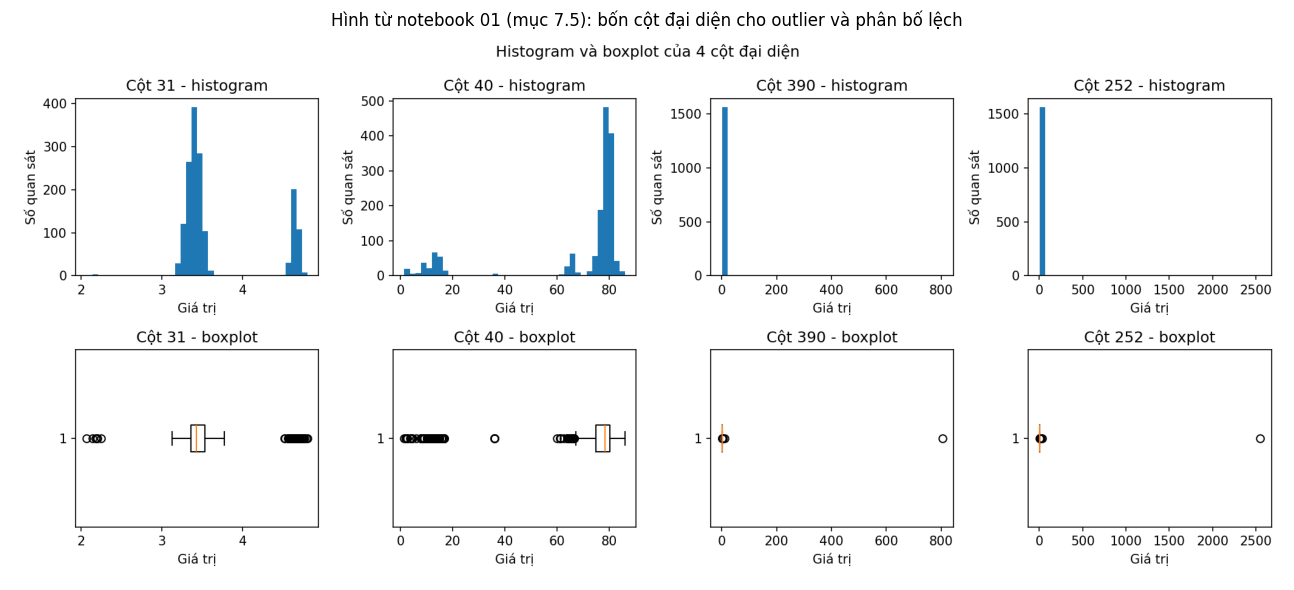

In [8]:
outlier_figure_path = FIGURES_DIR / "fig_01_outlier_examples.png"

if outlier_figure_path.exists():
    plt.figure(figsize=(14, 6))
    plt.imshow(plt.imread(outlier_figure_path))
    plt.axis("off")
    plt.title("Hình từ notebook 01 (mục 7.5): bốn cột đại diện cho outlier và phân bố lệch")
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có", outlier_figure_path.name, "- hãy chạy notebook 01 trước để có hình này.")

### Nhận xét

- **Phát hiện:** theo notebook 01, 110/464 cột có hơn 5% giá trị ngoài biên IQR (lớn nhất 22,62% ở cột 31) và 269/474 cột có |skew| > 2. Ở cột 31 và 40, phần bị luật IQR đánh dấu thực chất là cả một cụm giá trị thứ hai; ở cột 390 và 252, chỉ một giá trị rất lớn tách hẳn khỏi phần còn lại.
- **Ảnh hưởng:** luật IQR chỉ là công cụ sàng lọc. Xoá hay cắt các giá trị này khi chưa biết nguyên nhân có thể làm mất đúng những quan sát bất thường mà bài toán cần phát hiện, và SECOM không có thông tin để khẳng định đó là lỗi đo.
- **Kết luận:** **giữ nguyên outlier**, không xoá và không cắt. Hệ quả cần nhớ: `StandardScaler` dùng trung bình và độ lệch chuẩn nên bị giá trị cực trị kéo; mục 6 đếm lại mức độ này trên train. Việc thử `RobustScaler` hoặc clipping nằm ngoài phạm vi của bản rút gọn này.

## 5. Xây pipeline

*Nhãn: Kế thừa từ lab (Lab 02, cell 30 và cell 34–46).*

Dùng `MissingRateSelector` của thầy; `fit` chỉ trên train, `transform` cho test. Kết quả sau từng giai đoạn được lấy ra từ `named_steps` của chính pipeline đã fit, không fit imputer hay scaler riêng để làm bảng.

In [9]:
preprocessing_pipeline = Pipeline([
    ("missing_rate", MissingRateSelector(threshold=MISSING_THRESHOLD)),
    ("imputer", SimpleImputer(strategy="median")),
    ("constant", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler()),
])

# Chỉ fit trên train; test chỉ được transform bằng tham số đã học từ train
X_train_processed = preprocessing_pipeline.fit_transform(X_train_raw)
X_test_processed = preprocessing_pipeline.transform(X_test_raw)

print("Train sau pipeline:", X_train_processed.shape)
print("Test sau pipeline :", X_test_processed.shape)

Train sau pipeline: (1253, 466)
Test sau pipeline : (314, 466)


In [10]:
# Lấy từng bước ra từ pipeline đã fit
missing_selector = preprocessing_pipeline.named_steps["missing_rate"]
imputer = preprocessing_pipeline.named_steps["imputer"]
constant_selector = preprocessing_pipeline.named_steps["constant"]
scaler = preprocessing_pipeline.named_steps["scaler"]

# Kết quả sau từng giai đoạn - train
X_train_missing = missing_selector.transform(X_train_raw)
X_train_imputed = imputer.transform(X_train_missing)
X_train_nonconstant = constant_selector.transform(X_train_imputed)
X_train_scaled = scaler.transform(X_train_nonconstant)

# Kết quả sau từng giai đoạn - test
X_test_missing = missing_selector.transform(X_test_raw)
X_test_imputed = imputer.transform(X_test_missing)
X_test_nonconstant = constant_selector.transform(X_test_imputed)
X_test_scaled = scaler.transform(X_test_nonconstant)

n_removed_missing = int((~missing_selector.get_support()).sum())
n_removed_constant = int((~constant_selector.get_support()).sum())

print("Cột bị loại vì thiếu > 70% (học trên train):", n_removed_missing)
print("Cột bị loại vì hằng (học trên train)       :", n_removed_constant)
print("Cột còn lại:", X_train_scaled.shape[1])

# Chỉ số cột gốc (0-589) của các cột còn lại: notebook 03 sẽ cần để lần ngược tên cột
kept_after_missing = missing_selector.get_support(indices=True)
kept_original_columns = kept_after_missing[constant_selector.get_support(indices=True)]
print("Số chỉ số cột gốc còn lại:", len(kept_original_columns))

Cột bị loại vì thiếu > 70% (học trên train): 8
Cột bị loại vì hằng (học trên train)       : 116
Cột còn lại: 466
Số chỉ số cột gốc còn lại: 466


### Nhận xét

- **Phát hiện:** `MissingRateSelector` fit trên train loại 8 cột (590 → 582); `VarianceThreshold` loại thêm 116 cột (582 → 466); còn 466 cột cho cả train và test.
- **Ảnh hưởng:** test được biến đổi bằng đúng các cột, trung vị và μ, σ đã học từ train, nên không có thông tin nào của test đi vào bước học.
- **Kết luận:** pipeline đã fit một lần trên train, nhận 590 cột thô và trả về ma trận đã chuẩn hoá.

## 6. Kiểm tra sau tiền xử lý

*Nhãn: Kế thừa từ lab (Lab 02, cell 36–46); nhóm bổ sung: kiểm tra rò rỉ và đếm outlier còn lại.*

Kiểm tra shape, NaN, inf, nhãn và xác nhận không có thông tin từ test đi vào bước học.

In [11]:
# Số dòng giữ nguyên, hai tập có cùng số cột, nhãn khớp từng dòng
assert X_train_processed.shape[0] == len(y_train), "Số dòng train bị đổi"
assert X_test_processed.shape[0] == len(y_test), "Số dòng test bị đổi"
assert X_train_processed.shape[1] == X_test_processed.shape[1], "Train và test khác số cột"

validation_results = {
    "Số dòng train": X_train_processed.shape[0],
    "Số dòng test": X_test_processed.shape[0],
    "Số cột (train = test)": X_train_processed.shape[1],
    "NaN trong train": int(np.isnan(X_train_processed).sum()),
    "NaN trong test": int(np.isnan(X_test_processed).sum()),
    "Inf trong train": int(np.isinf(X_train_processed).sum()),
    "Inf trong test": int(np.isinf(X_test_processed).sum()),
    "Giá trị nhãn train": sorted(y_train.unique().tolist()),
    "Giá trị nhãn test": sorted(y_test.unique().tolist()),
}
for key, value in validation_results.items():
    print(f"{key}: {value}")

assert validation_results["NaN trong train"] == 0 and validation_results["NaN trong test"] == 0
assert validation_results["Inf trong train"] == 0 and validation_results["Inf trong test"] == 0

Số dòng train: 1253
Số dòng test: 314
Số cột (train = test): 466
NaN trong train: 0
NaN trong test: 0
Inf trong train: 0
Inf trong test: 0
Giá trị nhãn train: [0, 1]
Giá trị nhãn test: [0, 1]


In [12]:
# Train sau scale: mean ~ 0, std ~ 1. Test chỉ báo cáo, không ép về 0 và 1
train_means = X_train_processed.mean(axis=0)
train_stds = X_train_processed.std(axis=0)
test_means = X_test_processed.mean(axis=0)
test_stds = X_test_processed.std(axis=0)

print("Train - |mean| lớn nhất:", np.abs(train_means).max())
print("Train - std nhỏ nhất / lớn nhất:", train_stds.min(), "/", train_stds.max())
print("Test  - |mean| lớn nhất:", np.abs(test_means).max())
print("Test  - std nhỏ nhất / lớn nhất:", test_stds.min(), "/", test_stds.max())

Train - |mean| lớn nhất: 3.8800566909453676e-14
Train - std nhỏ nhất / lớn nhất: 0.9999999999999996 / 1.0000000000000004
Test  - |mean| lớn nhất: 0.18299896968731005
Test  - std nhỏ nhất / lớn nhất: 0.0 / 2.287847823769069


In [13]:
# Kiểm tra rò rỉ: trung vị dùng để điền thiếu phải là trung vị của TRAIN, không phải của test
train_median = np.nanmedian(X_train_missing, axis=0)
test_median = np.nanmedian(X_test_missing, axis=0)

same_as_train = np.allclose(imputer.statistics_, train_median)
n_columns_differ = int((~np.isclose(train_median, test_median)).sum())

print("Trung vị của imputer trùng trung vị train:", same_as_train)
print("Số cột có trung vị train khác trung vị test:", n_columns_differ, "/", len(train_median))
print("Trung vị hai tập khác nhau ở nhiều cột, nên nếu imputer học từ test thì kết quả điền sẽ khác.")
assert same_as_train, "Imputer không dùng trung vị của train"

# Kiểm tra scaler tương tự: mean_ và scale_ phải khớp train
print("Scaler.mean_ trùng mean của train:", np.allclose(scaler.mean_, X_train_nonconstant.mean(axis=0)))
print("Scaler.scale_ trùng std của train:", np.allclose(scaler.scale_, X_train_nonconstant.std(axis=0)))

Trung vị của imputer trùng trung vị train: True
Số cột có trung vị train khác trung vị test: 423 / 582
Trung vị hai tập khác nhau ở nhiều cột, nên nếu imputer học từ test thì kết quả điền sẽ khác.
Scaler.mean_ trùng mean của train: True
Scaler.scale_ trùng std của train: True


In [14]:
# So từng bước với đầu ra của pipeline: kết quả phải trùng nhau
max_diff_train = np.max(np.abs(X_train_scaled - X_train_processed))
max_diff_test = np.max(np.abs(X_test_scaled - X_test_processed))
print("Sai khác lớn nhất (từng bước so với pipeline) - train:", max_diff_train)
print("Sai khác lớn nhất (từng bước so với pipeline) - test :", max_diff_test)

Sai khác lớn nhất (từng bước so với pipeline) - train: 0.0
Sai khác lớn nhất (từng bước so với pipeline) - test : 0.0


In [15]:
# Outlier được giữ nguyên (mục 4): đếm mức độ còn lại trên train sau khi scale
abs_z_train = np.abs(X_train_processed)
n_extreme = int((abs_z_train > 5).sum())
n_columns_extreme = int((abs_z_train > 5).any(axis=0).sum())
n_values = abs_z_train.size

print("Giá trị train có |z| > 5:", n_extreme, "trên", n_values, f"({n_extreme / n_values * 100:.2f}%)")
print("Số cột có ít nhất một giá trị |z| > 5:", n_columns_extreme, "/", X_train_processed.shape[1])
print("|z| lớn nhất trên train:", abs_z_train.max())

Giá trị train có |z| > 5: 1804 trên 583898 (0.31%)
Số cột có ít nhất một giá trị |z| > 5: 345 / 466
|z| lớn nhất trên train: 35.38361202590827


### Nhận xét

- **Phát hiện:** sau pipeline không còn NaN hay inf; train và test cùng 466 cột, số dòng và nhãn giữ nguyên. Train sau scale có |mean| lớn nhất khoảng 3,9e-14 và std = 1 (sai số cỡ 1e-15). Test không bị ép về 0 và 1: |mean| lớn nhất 0,18 và std từ 0 đến 2,29. Std = 0 nghĩa là có cột mà mọi giá trị test đều bằng nhau sau khi điền thiếu, không phải lỗi.
- **Rò rỉ:** `imputer.statistics_` trùng trung vị của train, còn trung vị train và test khác nhau ở 423/582 cột, nên nếu imputer học từ test thì kết quả điền sẽ khác. `Scaler.mean_` và `scale_` cũng trùng thống kê của train. Kết quả từng bước trùng đầu ra pipeline (sai khác 0).
- **Outlier còn lại:** 1.804 trên 583.898 giá trị train (0,31%) có |z| > 5, rải ở 345/466 cột, lớn nhất |z| = 35,4. Đây là hệ quả của việc giữ outlier ở mục 4: ít về số lượng nhưng nằm ở đa số cột, và `StandardScaler` bị các giá trị này kéo.
- **Kết luận:** dữ liệu sẵn sàng đưa vào mô hình. Ở notebook 03, pipeline này chỉ dùng để nạp cấu hình; trong CV, mỗi fold sẽ `clone` và fit lại trên dữ liệu thô của fold đó.

## 7. Lưu pipeline bằng joblib

*Nhãn: Kế thừa từ lab (Lab 02, cell 48, 50); điều chỉnh: dùng `save_artifact`/`load_artifact`.*

Lưu, nạp lại và kiểm tra sai khác giữa hai lần transform bằng 0. Pipeline này nhận **590 cột thô**.

In [16]:
pipeline_path = save_artifact(preprocessing_pipeline, "preprocessing_pipeline.joblib")
print("Đã lưu:", pipeline_path.name, "-", round(pipeline_path.stat().st_size / 1024, 1), "KB")

loaded_pipeline = load_artifact("preprocessing_pipeline.joblib")
print("Bước đầu tiên sau khi nạp:", type(loaded_pipeline.named_steps["missing_rate"]).__name__)

Đã lưu: preprocessing_pipeline.joblib - 26.6 KB
Bước đầu tiên sau khi nạp: MissingRateSelector


In [17]:
X_train_reloaded = loaded_pipeline.transform(X_train_raw)
X_test_reloaded = loaded_pipeline.transform(X_test_raw)

diff_train = np.max(np.abs(X_train_processed - X_train_reloaded))
diff_test = np.max(np.abs(X_test_processed - X_test_reloaded))

print("Sai khác lớn nhất sau khi nạp lại - train:", diff_train)
print("Sai khác lớn nhất sau khi nạp lại - test :", diff_test)
print("np.allclose train:", np.allclose(X_train_processed, X_train_reloaded))
print("np.allclose test :", np.allclose(X_test_processed, X_test_reloaded))

assert np.allclose(X_train_processed, X_train_reloaded) and np.allclose(X_test_processed, X_test_reloaded)

Sai khác lớn nhất sau khi nạp lại - train: 0.0
Sai khác lớn nhất sau khi nạp lại - test : 0.0
np.allclose train: True
np.allclose test : True


### Nhận xét

- **Phát hiện:** pipeline lưu thành `preprocessing_pipeline.joblib`; nạp lại cho kết quả transform giống hệt bản gốc (sai khác lớn nhất 0,0 ở cả train và test, `np.allclose` đều True).
- **Ảnh hưởng:** file này chỉ đúng khi dùng cùng `secom_preprocessing.MissingRateSelector`, nên notebook nạp nó phải import được module của thầy.
- **Kết luận:** pipeline dùng lại được; notebook 03 sẽ nạp nó làm khuôn tiền xử lý rồi đặt vào pipeline đầy đủ với bước chọn đặc trưng và mô hình.

## 8. Tổng kết biến đổi của dữ liệu

*Nhãn: Kế thừa từ lab (Lab 02, cell 16: bảng tổng kết); điều chỉnh: số cột lấy từ pipeline đã fit trên train, có cả train và test.*

Bảng số dòng và số cột của **train và test** qua từng bước, rồi đối chiếu với các số tham chiếu của context.

In [18]:
stage_names = [
    "Dữ liệu thô",
    "Sau lọc cột thiếu > 70%",
    "Sau điền thiếu (median)",
    "Sau bỏ cột hằng",
    "Sau chuẩn hoá (scale)",
]
train_stages = [X_train_raw, X_train_missing, X_train_imputed, X_train_nonconstant, X_train_scaled]
test_stages = [X_test_raw, X_test_missing, X_test_imputed, X_test_nonconstant, X_test_scaled]

summary_rows = []
for name, train_part, test_part in zip(stage_names, train_stages, test_stages):
    summary_rows.append({
        "Bước": name,
        "Train - dòng": train_part.shape[0],
        "Train - cột": train_part.shape[1],
        "Test - dòng": test_part.shape[0],
        "Test - cột": test_part.shape[1],
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)

,Bước,Train - dòng,Train - cột,Test - dòng,Test - cột
0,Dữ liệu thô,1253,590,314,590
1,Sau lọc cột thiếu > 70%,1253,582,314,582
2,Sau điền thiếu (median),1253,582,314,582
3,Sau bỏ cột hằng,1253,466,314,466
4,Sau chuẩn hoá (scale),1253,466,314,466


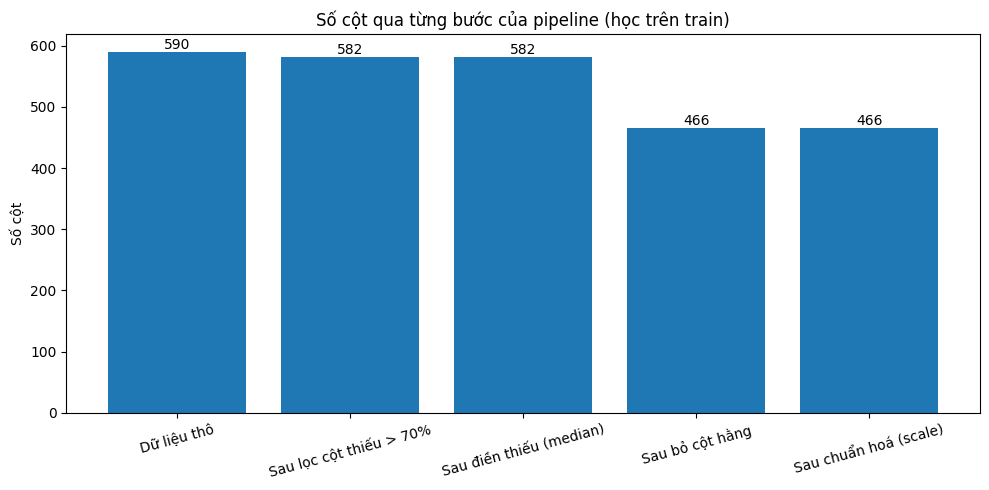

In [19]:
plt.figure(figsize=(10, 5))
plt.bar(summary_table["Bước"], summary_table["Train - cột"], color="tab:blue")
for position, value in enumerate(summary_table["Train - cột"]):
    plt.text(position, value + 5, str(value), ha="center")
plt.ylabel("Số cột")
plt.title("Số cột qua từng bước của pipeline (học trên train)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_02_feature_counts.png", dpi=150)
plt.show()

In [20]:
# Đối chiếu với số tham chiếu của context / lab. Hai dòng cuối của phần EDA là số mô tả trên toàn X,
# còn ở đây pipeline học trên train nên không bắt buộc phải khớp.
reference_rows = [
    ("Toàn bộ dữ liệu (dòng × cột)", "1567 × 590", f"{X.shape[0]} × {X.shape[1]}", "Bắt buộc"),
    ("Full Pass / Fail", "1463 / 104", f"{int((y == 0).sum())} / {int(y.sum())}", "Bắt buộc"),
    ("Train / Test (dòng)", "1253 / 314", f"{len(train_idx)} / {len(test_idx)}", "Bắt buộc"),
    ("Train Pass / Fail", "1170 / 83", f"{int((y_train == 0).sum())} / {int(y_train.sum())}", "Bắt buộc"),
    ("Test Pass / Fail", "293 / 21", f"{int((y_test == 0).sum())} / {int(y_test.sum())}", "Bắt buộc"),
    ("Cột thiếu > 70% (EDA toàn X → pipeline học trên train)", "8", str(n_removed_missing), "Mô tả, không bắt buộc"),
    ("Cột hằng (EDA toàn X → pipeline học trên train)", "116", str(n_removed_constant), "Mô tả, không bắt buộc"),
    ("Số cột sau hai bước loại (EDA toàn X → pipeline)", "582 rồi 466", f"{X_train_missing.shape[1]} rồi {X_train_scaled.shape[1]}", "Mô tả, không bắt buộc"),
]

reference_table = pd.DataFrame(reference_rows, columns=["Kiểm tra", "Tham chiếu", "Kết quả notebook", "Loại"])
reference_table["Khớp"] = np.where(
    reference_table["Tham chiếu"] == reference_table["Kết quả notebook"], "Có", "Không"
)
with pd.option_context("display.max_colwidth", None):
    display(reference_table)

required_rows = reference_table[reference_table["Loại"] == "Bắt buộc"]
assert (required_rows["Khớp"] == "Có").all(), "Có số bắt buộc không khớp tham chiếu"
print("Các số bắt buộc (5 dòng đầu) đều khớp tham chiếu.")

,Kiểm tra,Tham chiếu,Kết quả notebook,Loại,Khớp
0,Toàn bộ dữ liệu (dòng × cột),1567 × 590,1567 × 590,Bắt buộc,Có
1,Full Pass / Fail,1463 / 104,1463 / 104,Bắt buộc,Có
2,Train / Test (dòng),1253 / 314,1253 / 314,Bắt buộc,Có
3,Train Pass / Fail,1170 / 83,1170 / 83,Bắt buộc,Có
4,Test Pass / Fail,293 / 21,293 / 21,Bắt buộc,Có
5,Cột thiếu > 70% (EDA toàn X → pipeline học trên train),8,8,"Mô tả, không bắt buộc",Có
6,Cột hằng (EDA toàn X → pipeline học trên train),116,116,"Mô tả, không bắt buộc",Có
7,Số cột sau hai bước loại (EDA toàn X → pipeline),582 rồi 466,582 rồi 466,"Mô tả, không bắt buộc",Có


Các số bắt buộc (5 dòng đầu) đều khớp tham chiếu.


### Nhận xét

- **Phát hiện:** train đi từ 590 → 582 → 582 → 466 → 466 cột qua năm giai đoạn; test luôn có đúng cùng số cột với train ở mọi bước, số dòng giữ nguyên (1.253 và 314).
- **So với EDA:** khi học trên train, pipeline loại 8 cột thiếu > 70% và 116 cột hằng, đúng bằng số đếm trên toàn bộ `X` ở notebook 01 (8 và 116), nên 582 rồi 466 cũng khớp.
- **Kết luận:** các số bắt buộc (1567 × 590, 1463/104, 1253/314, 1170/83, 293/21) khớp tham chiếu.

## Kết luận

Notebook này chuẩn bị dữ liệu SECOM cho bước mô hình hoá. Dữ liệu 1.567 × 590 được chia stratified 80/20 (seed 42) thành train 1.253 mẫu (83 Fail) và test 314 mẫu (21 Fail) trước khi học bất kỳ tham số nào. Pipeline `MissingRateSelector → median imputer → VarianceThreshold(0) → StandardScaler` chỉ fit trên train: loại 8 cột thiếu hơn 70% và 116 cột hằng, còn 466 cột, trùng số đếm ở notebook 01. Sau pipeline không còn NaN hay inf, train có mean ≈ 0 và std ≈ 1, và imputer thật sự dùng trung vị của train (trung vị test khác ở 423/582 cột). Outlier được giữ nguyên: 0,31% giá trị train có |z| > 5, lớn nhất 35,4, nên `StandardScaler` bị các giá trị này kéo. Pipeline lưu và nạp lại cho kết quả giống hệt. Hạn chế: test chỉ có 21 Fail, random split có thể lạc quan khi dữ liệu đổi theo thời gian. Notebook 03 sẽ gọi lại `get_split`, nạp `preprocessing_pipeline.joblib` và đặt nó cùng bước chọn đặc trưng, mô hình vào pipeline đầy đủ để chạy CV trên dữ liệu thô của train.

## Điểm cần ghi nhớ

- Chia train/test **trước**, rồi mới fit mọi bước học tham số; test chỉ được `transform`.
- Split không lưu ra file: mỗi notebook gọi `get_split(y)` và kiểm tra 1253 / 314, Fail 83 / 21.
- Pipeline 4 bước nhận 590 cột thô và trả về 466 cột đã chuẩn hoá; lưu tại `artifacts/preprocessing_pipeline.joblib`.
- Giữ outlier nên `StandardScaler` bị giá trị cực trị kéo (|z| lớn nhất 35,4 trên train).
- Notebook 03 không đưa ma trận đã biến đổi này vào CV; trong CV mỗi fold fit lại cả chuỗi từ dữ liệu thô.
- Nạp pipeline cần import được `secom_preprocessing.MissingRateSelector`.